In [ ]:
#sequential graph
from langgraph.graph import StateGraph,START ,END
from typing import TypedDict


In [3]:
class bmiState(TypedDict):
    weight_kg:float
    height_m:float
    bmi:float
    category:str
    

In [6]:
def bmi_calculator(state :bmiState)->bmiState:
   
    weight=state['weight_kg']
    height=state['height_m']
    
    state['bmi']=weight/(height**2)
    return state

In [4]:
def label_bmi(state:bmiState)-> bmiState:
    if state["bmi"] < 18.5:
        state["category"]="Underweight"
    elif state["bmi"] >= 18.5 and state["bmi"] < 25:
        state["category"]= "Normal weight"
    elif state["bmi"] >= 25 and state["bmi"] < 30:
        state["category"]= "Overweight"
    else:
        state["category"]= "Obese"
    
    return state

In [8]:
graph=StateGraph(bmiState)

graph.add_node("cal_bmi",bmi_calculator)
graph.add_node("bmi_lab",label_bmi)

graph.add_edge(START,"cal_bmi")
graph.add_edge("cal_bmi","bmi_lab")
graph.add_edge("bmi_lab",END)

workflow=graph.compile()

In [10]:
intial_state={ "weight_kg":80 ,"height_m":2.0}
final_state=workflow.invoke(intial_state)
final_state

{'weight_kg': 80, 'height_m': 2.0, 'bmi': 20.0, 'category': 'Normal weight'}

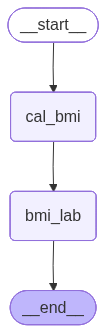

In [9]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())